# Project Milestone One: Gathering your Team, Understanding the Problem,  Exploring the Data

#### Due: Midnight on March 29th (with 2-hour grace period)  

#### There will be no late period on this homework, as we need to start manual grading immediately!



### What We Will Do in This Milestone Assignment

1. You will convene your team and fill out the Team Contract (in the Homework Repo), to be submitted to Gradescope.
2. You must select a team leader for the purpose of submitting this notebook, after the team collaborates to complete the assignment. This <a href=https://guides.gradescope.com/hc/en-us/articles/21863861823373-Adding-Group-Members-to-a-Submission>link</a> describes how to add group members to your leader's submission.
3. At the conclusion of your work on this Milestone, you will complete an Individual Evaluation of your team's work (in the Homework Repo) and upload it *individually* to Gradescope.
4. We will follow a simplified version of the **Machine Learning Project Checklist** in Appendix A in our textbook *Hands-On Machine Learning* (pp.779):  

>Part 1:	Frame the problem and look at the big picture  
Part 2: Download and perform preliminary exploration of the data  
Part 3: Clean the Data: Drop, Impute, and Encode   
Part 4: Explore Feature Relationships  
Part 5: Investigate Feature Engineering options to better expose the underlying data patterns  

### The Dataset

All teams will use the same dataset. It is a smaller version of the Zillow housing dataset that was used in the
Zillow Million Dollar Prize which ran on Kaggle in 2017 (sorry, the contest is closed, so you can't win any money
with this project!).  We will try to predict the assessed tax value (`'taxvaluedollarcnt'`) of the property from a large collection
of descriptors. Some features are closely related and some are obviously useless.  There are potential outliers and also quite a few missing values.

This is a good example of a dataset which has not been predigested for you on Kaggle, and should give you a good chance to
try all the various tools in your toolbox!


In [ ]:
# =============================
# Useful Imports
# =============================

# Standard Libraries
import os
import time
import math
import io
import zipfile
import requests
from urllib.parse import urlparse
from itertools import chain, combinations

# Data Science Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import polars as pl

# Visualization
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.ticker as mticker  # Optional: Format y-axis labels as dollars

# Scikit-learn (Machine Learning)
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV,
    RandomizedSearchCV,
    RepeatedKFold
)
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error
from sklearn.feature_selection import SequentialFeatureSelector, f_regression, SelectKBest
from sklearn.datasets import make_regression
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor
from scipy.spatial import cKDTree

# Kaggle and Progress Tracking
from tqdm import tqdm

# =============================
# Global Variables
# =============================
random_state = 42

# =============================
# Utility Functions
# =============================

# Format y-axis labels as dollars with commas (optional)
def dollar_format(x, pos):
    return f'${x:,.0f}'

# Convert seconds to HH:MM:SS format
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))



## Prelude: Download the Zillow Housing Dataset

The code cell below will load the dataset for you.    

> **Notice that before downloading, this cell first checks whether the files already exist.**

For a detailed description of the dataset features, please refer to  **Appendix 1** below.

**Note:** Do **not** perform a train/test split for this milestone (unlike HOML suggests), since you need to do the split **after** any data preparation and feature engineering. You can wait until Milestone 2 to do the split.

In [ ]:

url = "https://www.cs.bu.edu/fac/snyder/cs505/Data/zillow_dataset.csv"

filename = os.path.basename(urlparse(url).path)

if not os.path.exists(filename):
    try:
        print("Downloading the file...")
        response = requests.get(url)
        response.raise_for_status()  # Raise an error for bad status codes
        with open(filename, "wb") as f:
            f.write(response.content)
        print("File downloaded successfully.")
    except requests.exceptions.RequestException as e:
        print(f"Error downloading the file: {e}")
else:
    print("File already exists. Skipping download.")

df = pd.read_csv(filename)

File downloaded successfully.


## Part 1: Frame the problem and look at the big picture [3 pts]

This part is a bit vague, since this project is not taking place in an actual business, but for the sake of exercizing all the steps, **pretend** that you are working at Zillow as a data analyst and are given this dataset and asked to
- Analyze and understand the data;
- Create a regression model;
- Give a presentation to the marketing team about your results.  

#### **1 Discussion:**

AFTER doing your EDA, come back and answer each of the following 3 questions in a *concise and informative paragraph between the lines;* you may wish to use your own business or home-buying experience, or to do some online research about the issues before you propose your ideas. (Don't stress about this, but *humor your professor and give it your best shot!*)


**1.1:**  What is the objective of this project in business terms?


The objective of this project is to identify undervalued properties for the purpose of investment.

**1.2:**  How will your solution be used?


Our model will be used by real estate investors to aid in the acquisition of properties by identifying prime investment targets.

**1.3:**  How should success (or failure) be measured?


Success should be measured based on how the model performs as well as investment returns when using the model. If the model is successfully identifying undervalued properties, then returns should reflect that.

## Part 2: Download and perform preliminary exploration of the data [4 pts]

### Part 2.A: Load the data into a dataframe and study each feature/column and its characteristics:
- Name
- Type (categorical, int/float, text, etc.)
- Apparent usefulness for the task
- Approximate % of missing values
- How many unique values

**Note:** The **target** is the last column `'taxvaluedollarcnt'` -- pay particular attention to this during the EDA process.
  
Hint: Just use `.head()`, `.info()`, and `.nunique()`.

In [ ]:
df_zillow = pd.read_csv('zillow_dataset.csv')

total_rows = len(df_zillow)
print(f"The Zillow dataset has {len(df_zillow)} rows and {len(df_zillow.columns)} columns.")
for i, column in enumerate(df_zillow.columns):
    print(f"{str(i + 1)}: {column}")
    print(f"Type: {df_zillow[column].dtype}")
    print(f"Unique Values: {df_zillow[column].nunique()} ({df_zillow[column].nunique() / total_rows * 100:.2f}%)")
    print(f"Null Values: {df_zillow[column].isna().sum()} ({df_zillow[column].isna().sum() / total_rows * 100:.2f}%)")
    print("----")

The Zillow dataset has 77613 rows and 55 columns.
1: parcelid
Type: int64
Unique Values: 77414 (99.74%)
Null Values: 0 (0.00%)
----
2: airconditioningtypeid
Type: float64
Unique Values: 5 (0.01%)
Null Values: 52606 (67.78%)
----
3: architecturalstyletypeid
Type: float64
Unique Values: 5 (0.01%)
Null Values: 77406 (99.73%)
----
4: basementsqft
Type: float64
Unique Values: 43 (0.06%)
Null Values: 77563 (99.94%)
----
5: bathroomcnt
Type: float64
Unique Values: 22 (0.03%)
Null Values: 34 (0.04%)
----
6: bedroomcnt
Type: float64
Unique Values: 16 (0.02%)
Null Values: 34 (0.04%)
----
7: buildingclasstypeid
Type: float64
Unique Values: 2 (0.00%)
Null Values: 77598 (99.98%)
----
8: buildingqualitytypeid
Type: float64
Unique Values: 12 (0.02%)
Null Values: 27804 (35.82%)
----
9: calculatedbathnbr
Type: float64
Unique Values: 21 (0.03%)
Null Values: 650 (0.84%)
----
10: decktypeid
Type: float64
Unique Values: 1 (0.00%)
Null Values: 76999 (99.21%)
----
11: finishedfloor1squarefeet
Type: float64
U

#### **2.A Discussion:** Answer the following questions.

**2.A.1:**  Which features are categorical?

The following features are categorical:
 * `parcelid`
    * ID column, technically categorical, will be dropped
 * `airconditioningtypeid`
    * Type of cooling system present in the home (if any)
 * `architecturalstyletypeid`
    * Architectural style of the home (i.e. ranch, colonial, split-level, etc…)
 * `buildingclasstypeid`
    * The building framing type (steel frame, wood frame, concrete/brick)
 * `buildingqualitytypeid`
    * Overall assessment of condition of the building
 * `decktypeid`
    * Type of deck (if any) present on parcel
 * `fips`
    * Federal Information Processing Standard code
 * `hashottuborspa`
    * Does the home have a hot tub or spa
 * `heatingorsystemtypeid`
    * Type of home heating system
 * `pooltypeid10`
    * Spa or Hot Tub
 * `pooltypeid2`
    * Pool with Spa/Hot Tub
 * `pooltypeid7`
    * Pool without hot tub
 * `propertycountylandusecode`
    * County land use code i.e. it's zoning at the county level
 * `propertylandusetypeid`
    * Type of land use the property is zoned for
 * `regionidcity`
    * City in which the property is located (if any)
 * `regionidcounty`
    * County in which the property is located
 * `regionidneighborhood`
    * Neighborhood in which the property is located
 * `regionidzip`
    * Zip code in which the property is located
 * `storytypeid`
    * Type of floors in a multi-story house (i.e. basement and main level, split-level, attic, etc.)
 * `typeconstructiontypeid`
    * What type of construction material was used to construct the home
 * `fireplaceflag`
    * Is a fireplace present in this home
 * `taxdelinquencyflag`
    * Property taxes for this parcel are past due as of 2015

**2.A.2:**  Are there any features which appear at first glance to be **useless** for the business purpose of this project and should be deleted?  Give examples and describe your reasoning briefly.

Features to drop at first glance:
 * `parcelid`
    * ID column, holds no meaningful relation to target column

**2.A.3:**  Are there any features which appear to be **useless** because of the percentage of missing values?  If so, give an example.

Features to drop due to high null count percentage:
 * `airconditioningtypeid`
    * 67.78% null values
 * `architecturalstyletypeid`
    * 99.73% null values
 * `basementsqft`
    * 99.94% null values
 * `buildingclasstypeid`
    * 99.98% null values
 * `decktypeid`
    * 99.21% null values
 * `finishedfloor1squarefeet`
    * 92.22% null values
 * `finishedsquarefeet13`
    * 99.95% null values
 * `finishedsquarefeet15`
    * 96.10% null values
 * `finishedsquarefeet50`
    * 92.22% null values
 * `finishedsquarefeet6`
    * 99.50% null values
 * `fireplacecnt`
    * 89.32% null values
 * `garagecarcnt`
    * 67.12% null values
 * `garagetotalsqft`
    * 67.12% null values
 * `hashottuborspa`
    * 98.02% null values
 * `poolcnt`
    * 79.16% null values
 * `poolsizesum`
    * 98.88% null values
 * `pooltypeid10`
    * 99.40% null values
 * `pooltypeid2`
    * 98.62% null values
 * `pooltypeid7`
    * 80.57% null values
 * `storytypeid`
    * 99.94% null values
 * `threequarterbathnbr`
    * 86.98% null values
 * `typeconstructiontypeid`
    * 99.71% null values
 * `yardbuildingsqft17`
    * 96.92% null values
 * `yardbuildingsqft26`
    * 99.91% null values
 * `numberofstories`
    * 77.32% null values
 * `fireplaceflag`
    * 99.78% null values
 * `taxdelinquencyflag`
    * 96.26% null values
 * `taxdelinquencyyear`
    * 96.26% null values

**2.A.4:**  Are there any features which appear to be **useless** because of the number of unique values?  If so, give an example.

Features to drop due to number of unique values:
 * `regionidneighborhood`
   * 60.09% null values combined with large number of unique values (0.62%)
 * `propertyzoningdesc`
   * seems to be primarily random strings, with too high a unique value count (2.46%) to be considered categorical
 * `propertycountylandusecode`
   * seems to be primarily random strings, with too high a unique value count (0.1%) to be considered categorical

### Part 2.B: Exploratory Data Analysis (EDA) -- Feature-Level Visualization  

- To get an overview, generate histograms for all features using `df.hist()`  (Hint: increase the figsize and set the layout to `(-1,m)` to get  `m` columns and as many rows as necessary.)
- Generate individual visualizations for the **target and three (3)** other interesting-looking features in the dataset (i.e., a total of 4):  
    - Use appropriate plot types (e.g., histograms and boxplots for numerical features, bar plots for categorical features) to understand distributions and identify potential outliers for these three.
    - Use as many code cells as you need, and give comments describing what each cell does.
    - Answer the discussion question posed (you should choose 3 features for which you can say something interesting in the discussion).  

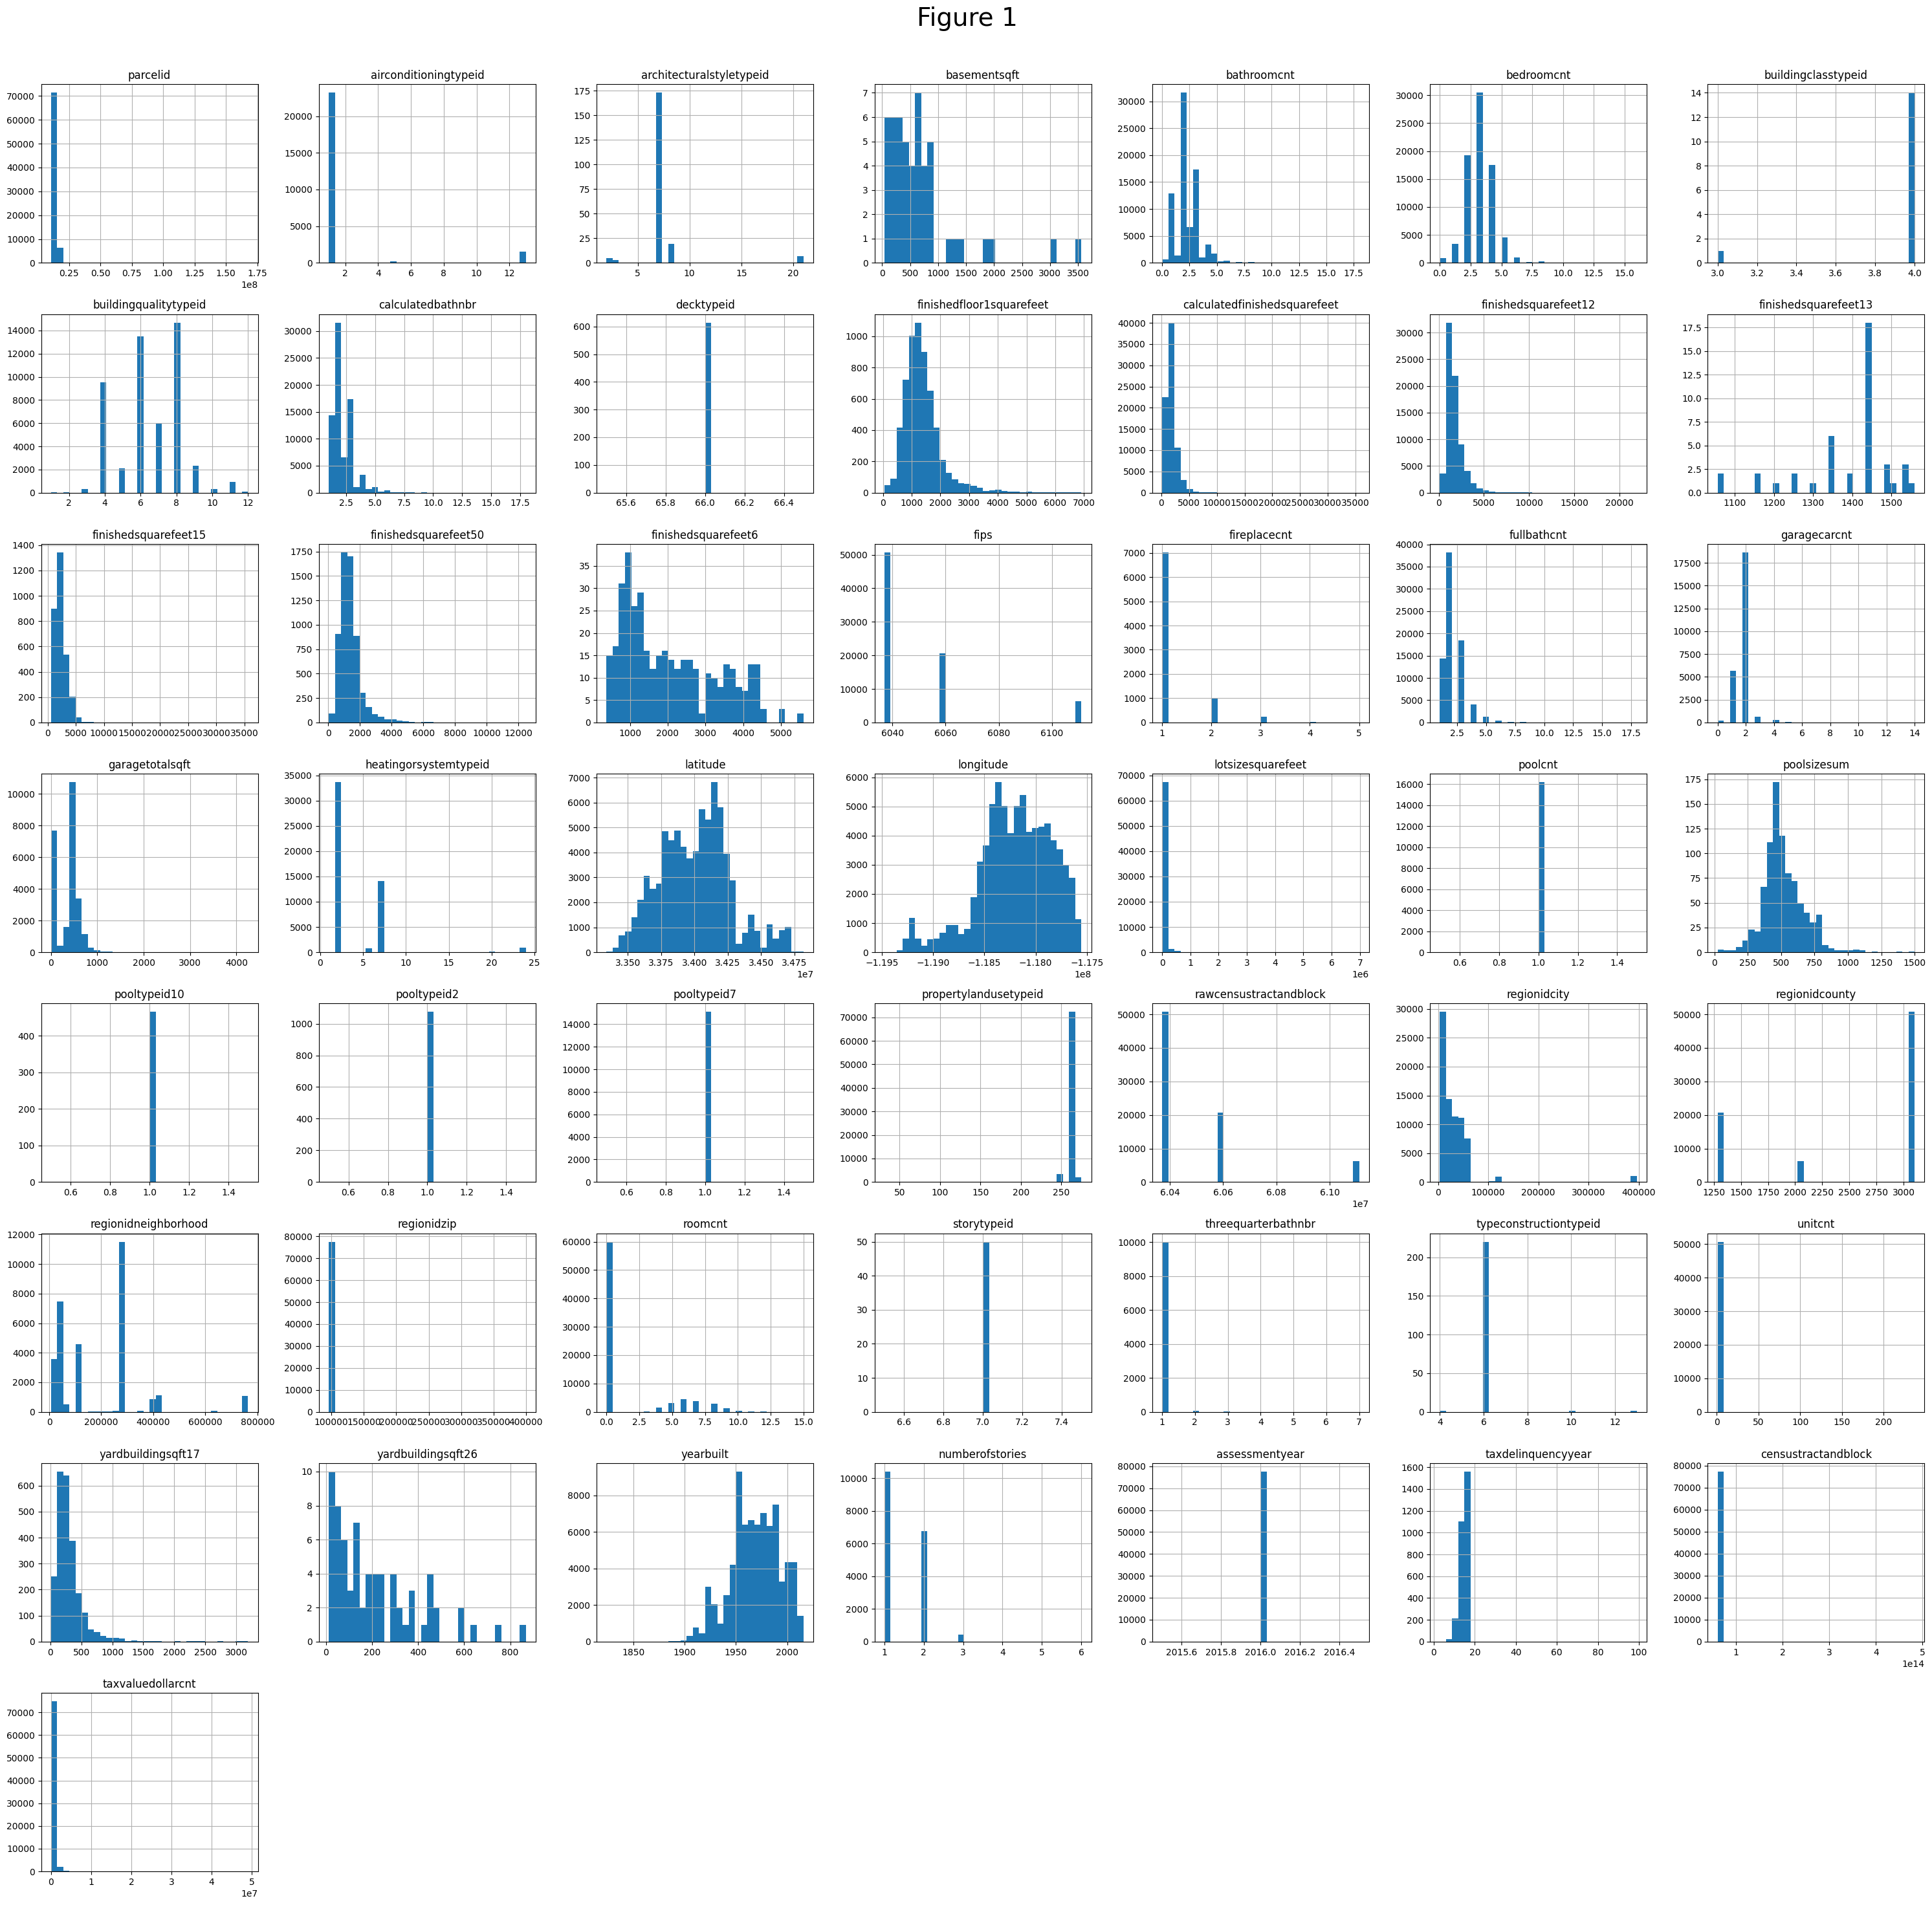

In [ ]:
# Histograms for all features
df_zillow.hist(figsize=(30, 30), bins=32)

plt.suptitle('Figure 1', fontsize=28)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

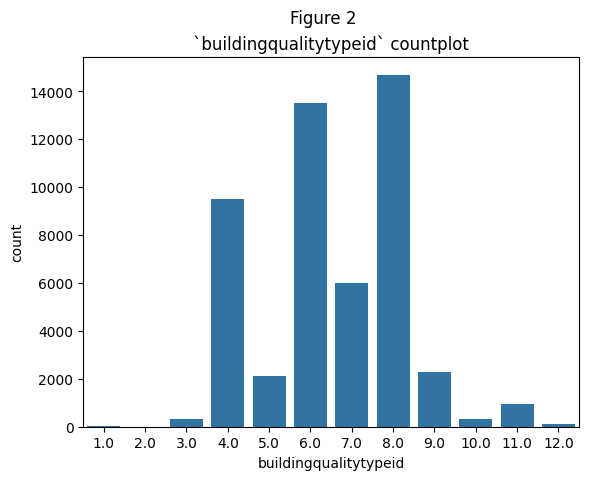

In [ ]:
# Individual Visualizations

# Feature 1: buildingqualitytypeid
sns.countplot(
    data=df_zillow,
    x='buildingqualitytypeid'
)

plt.suptitle('Figure 2')
plt.title('`buildingqualitytypeid` countplot')
plt.show()

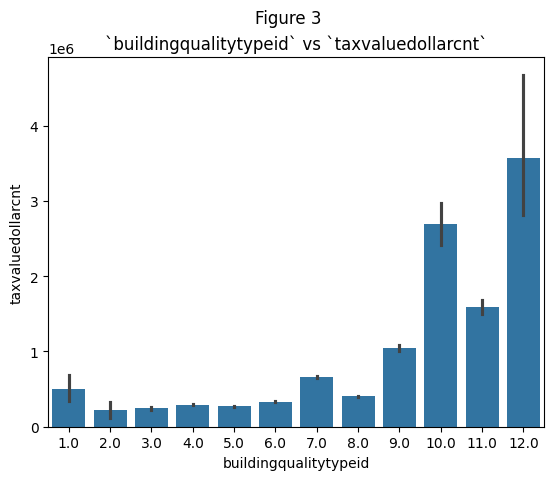

In [ ]:
sns.barplot(data=df, x='buildingqualitytypeid', y='taxvaluedollarcnt')

plt.suptitle('Figure 3')
plt.title('`buildingqualitytypeid` vs `taxvaluedollarcnt`')
plt.show()

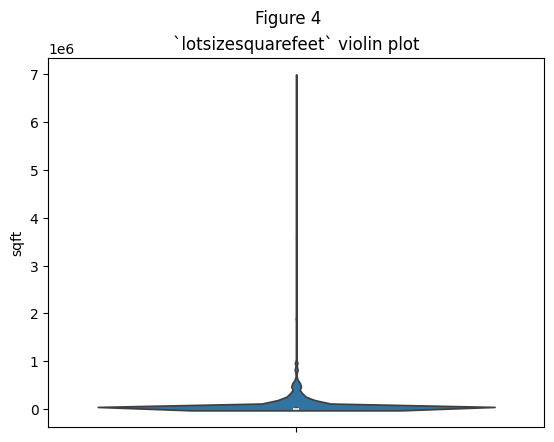

In [ ]:
# Feature 2: lotsizesquarefeet
sns.violinplot(
    data=df_zillow,
    y="lotsizesquarefeet",
)

plt.suptitle('Figure 4')
plt.title('`lotsizesquarefeet` violin plot')
plt.ylabel('sqft')
plt.show()

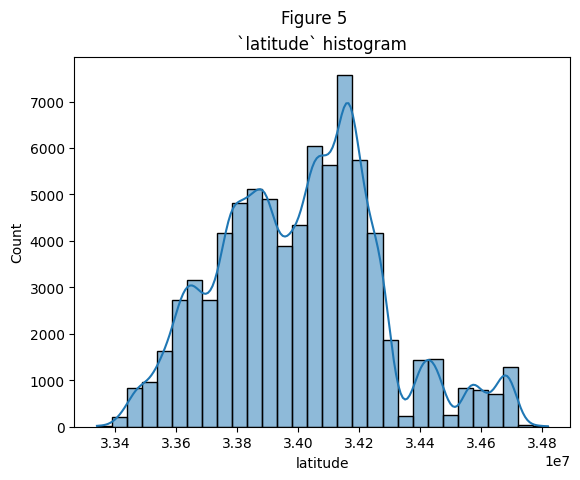

In [ ]:
# Feature 3: latitude
sns.histplot(
    data=df_zillow,
    x="latitude",
    kde=True,
    bins=30
)

plt.suptitle('Figure 5')
plt.title('`latitude` histogram')
plt.show()

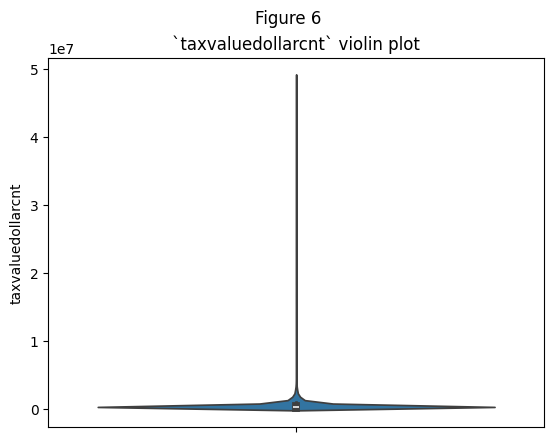

In [ ]:
# Target: taxvaluedollarcnt
sns.violinplot(
    data=df_zillow,
    y='taxvaluedollarcnt'
)

plt.suptitle('Figure 6')
plt.title('`taxvaluedollarcnt` violin plot')
plt.show()

#### **2.B Discussion:** Describe in a paragraph what you learned in your detailed examination of the features you explored:
- What is the distribution (normal, exponential, etc.) if any?
- Any problems (e.g., outliers, any odd characteristics)?
- Anything else interesting? Why did you choose it?


The features I explored were `buildingqualitytypeid`, `lotsizesquarefeet`, `latitude`, and the target `taxvaluedollarcnt`. The first feature I chose, `buildingqualitytypeid`, is a rating from 1-12, where 1 is the worst and 12 is the best. I expected this feature to be a normal distribution, but was curious if there would be a positive skew indicating more low to mid value homes, or a negative skew indicating more mid to high level homes. What I discovered was a roughly normal distribution with a negative skew meaning that the dataset contained more mid to high value homes than low value (see figure 2). There are a couple of strange dips at rankings 5 and 7 that I cannot quite explain. The next feature I explored was `lotsizesquarefeet`. I specifically wanted to visualize this feature in a way that highlighted outliers, hence my choice to use a violin plot as seen in figure 4. What I found was that there is a major upper outlier region. This aligns with the histogram which shows a distribution with a major positive skew. When cleaning the data it may be best to drop the rows that contains outliers for this feature. The last feature I examined before looking at the target was `latitude`. I was curious with this feature to see what the distribution would look like and if there were any geographic clusters. The distribution, as seen in figure 5, is multimodal (three distinct clusters by the look of it), with a slight positive skew. This matches intuition, as you would expect to see multiple clusters and not a uniform distribution due to how population density fluctuates. Given these three distinct clusters, I am curious if this feature would be a candidate for K-means clustering. It is also likely that these three distinct clusters are represented in the `fips` feature, meaning it may be best to drop the feature entirely. Finally, I visualized the target, `taxvaluedollarcnt` with a violin plot as well to examine outliers (see figure 6). Similar to the `lotsizesquarefeet` feature, I noticed another major upper outlier region. Whether or not to drop these rows containing `taxvaluedollarcnt` outliers is debatable as dropping them could lead to undervaluations on expensive homes.

## Part 3:  Clean the Data: Drop, Impute, and Encode [6 pts]



**Important Notes:**
- You should review your Homework 4 before doing this section!
- Create new names for modified data at each stage to avoid problems with global variables.
- Whenever possible, write functions for all data transformations you apply, for these reasons:
    - So you can easily prepare the data the next time you get a fresh dataset
    - So you can apply these transformations in future projects
    - To clean and prepare new data instances once your solution is live
    - To make it easy to treat your preparation choices as hyperparameters
    - [To apply the same transformations to your test set if train/test split already done -- not applicable here]

### Part 3.A: Drop features you judge to be unsuitable for the regression task

Your call, based on any research you can do to understand the feature (hopefully IRL you would have a domain expert to help with this, but do your best).   

Note: Do not drop features because of too many missing values, that's the next task!

In [ ]:
df_houses = df_zillow.copy()

df_houses = df_houses.drop(columns = ['parcelid', 'regionidneighborhood', 'propertycountylandusecode', 'propertyzoningdesc'])

print("Orignal Dataset: ", len(df_zillow.columns))
print()
print("New Dataset with drops: ", len(df_houses.columns))

Orignal Dataset:  55

New Dataset with drops:  51


#### **3.A Discussion:** Justify in a paragraph your decisions about which features to drop.


We decided to remove features that were unlikely to provide good predictive values due to their uniqueness or lack of patterns. `Parcelid` was dropped because it is a unique identifier for each property and does not help when trying to predict the target variable.  `regionidneighborhood`, `propertycountylandusecode`, and `propertyzoningdesc` were removed because they contain a large number of unique values and would introduce to much noise in the dataset.

### Part 3.B: Drop **features** with "too many" null values

Your code in the next cell(s). Make a judgement call about what "too many" means and briefly describe your reasoning in the discussion.   

Note: "Too many" may depend on what the non-null values look like, be sure to investigate carefully.

In [ ]:
df_drop_nulls = df_houses.copy()

df_drop_nulls = df_drop_nulls.drop(columns = [
    'airconditioningtypeid',
    'architecturalstyletypeid',
    'basementsqft',
    'buildingclasstypeid',
    'decktypeid',
    'finishedfloor1squarefeet',
    'finishedsquarefeet13',
    'finishedsquarefeet15',
    'finishedsquarefeet50',
    'finishedsquarefeet6',
    'fireplacecnt',
    'garagecarcnt',
    'garagetotalsqft',
    'hashottuborspa',
    'poolcnt',
    'poolsizesum',
    'pooltypeid10',
    'pooltypeid2',
    'pooltypeid7',
    'storytypeid',
    'threequarterbathnbr',
    'typeconstructiontypeid',
    'yardbuildingsqft17',
    'yardbuildingsqft26',
    'numberofstories',
    'fireplaceflag',
    'taxdelinquencyflag',
    'taxdelinquencyyear'
])

print("Orignal Dataset: ", len(df_zillow.columns))
print()
print("New Dataset with drops: ", len(df_houses.columns))
print()
print("Dataset After Null Values dropped", len(df_drop_nulls.columns))

Orignal Dataset:  55

New Dataset with drops:  51

Dataset After Null Values dropped 23


#### **3.B Discussion:** In a paragraph, explain your decision about which features were dropped



We removed null values that had above 65% mostly because it made the values unreliable for modeling. We did not want to have a high bias in this modeling which is why we picked null values over 65%. By removing these features, we improved the overall quality of the dataset and reduced the risk of introducing noise through excessive imputation.

### Part 3.C: Drop Problematic **samples**

There could be several reasons why you might want to drop a sample:
- It has  "too many" null values
- It has a null value in the target
- It contains outliers, especially in the target



Your code in the next cell(s). Make a judgement call about which samples should be dropped and briefly describe your reasoning in the discussion.   


In [ ]:
df_samples = df_drop_nulls.copy()

df_samples = df_samples.dropna(subset = ['taxvaluedollarcnt'])

rich_houses = df_samples["taxvaluedollarcnt"].quantile(0.99)

df_samples = df_samples[df_samples["taxvaluedollarcnt"] <= rich_houses]

print("Orignal Dataset: ", len(df_zillow))
print()
print("Dataset With Sample Dropped", len(df_samples))

Orignal Dataset:  77613

Dataset With Sample Dropped 76802


#### **3.C Discussion:** In a short paragraph, explain your decision about which samples were dropped


We dropped all rows were `taxvaluedollarcnt` was missing. Then, we dropped extreme values in the 99th percentile. The values represent high priced properties that can classify as outliers and reduce the model's ability to generalize.

### Part 3.D: Impute for the remaining missing values

Review the methods for imputation in **Appendix 2** and choose how you will impute the remainder of the missing values. Note:
- Consider whether different methods are justified for different features.
- In the next cells, apply your imputation methods to the dataset so that no null values remain after this step.
- Answer the discussion question.

In [ ]:
df_impute = df_samples.copy()

numerica_cols = df_impute.select_dtypes(include = ['float64', 'int64']).columns

numerica_imp = SimpleImputer(strategy = 'median')
df_impute[numerica_cols] = numerica_imp.fit_transform(df_impute[numerica_cols])

print("The Remaning Null Values are this many :", df_impute.isnull().sum().sum())

The Remaning Null Values are this many : 0


#### **3.D Discussion:**  Describe in a paragraph your decisions about which methods you used to impute missing values in the dataset


We handled the remaining missing values using imputation. Since all remaining features were numerical, we applied median imputation to fill missing values because it is robust to outliers and towards skewed distributions. This ensured that no null values remained in the dataset.

### 3.E: Encode the Categorical Features (if any)

You may not have any categorical features. If you do, encode them in the next step. No discussion is necessary.

## Part 4:  Investigate Feature Relationships  [6 pts]

In this part, we will investigate the feature relationships as a way of understanding the data.  In the next part, we'll investigate potential feature engineering opportunities.

**Note:**  We won't be committing to any changes to the data until Milestone 2, as our choice of transformations will very much depend on the model we're building. But investigating these aspects of the data is an essential step in the first stages of our project.

### Part 4.A:

   - Compute and analyze pairwise correlations using a correlation matrix.
   - Compute the F-statistic for all features for a better view of the relationships (displaying them in a bar chart would be useful as well).
   - Identify features with strong correlations or notable relationships that may impact model performance.
   - Investigate forward and backward feature selection
        - Run these algorithms to investigate possible feature selection (don't commit to any selections yet)

Your code below, in multiple cells with descriptive comments.

In [ ]:
# Dataset copy
df_relations = df_impute.copy()

# Correlation Matrix
correlation_matrix = df_relations.corr()

# Wtih target value
correlation_targets = correlation_matrix['taxvaluedollarcnt'].sort_values(ascending = False)

print(correlation_targets)

taxvaluedollarcnt               1.000000
finishedsquarefeet12            0.590901
calculatedfinishedsquarefeet    0.578143
calculatedbathnbr               0.490084
bathroomcnt                     0.476848
fullbathcnt                     0.468577
buildingqualitytypeid           0.265844
bedroomcnt                      0.264027
yearbuilt                       0.171214
fips                            0.037826
rawcensustractandblock          0.036662
roomcnt                         0.025643
unitcnt                         0.010855
censustractandblock             0.006488
regionidzip                     0.004393
longitude                      -0.014476
regionidcity                   -0.018956
propertylandusetypeid          -0.037409
lotsizesquarefeet              -0.038519
regionidcounty                 -0.087521
heatingorsystemtypeid          -0.141413
latitude                       -0.146420
assessmentyear                       NaN
Name: taxvaluedollarcnt, dtype: float64


In [ ]:
X = df_relations.copy()

# Splitting X and y into values
X = X.drop(columns = ["taxvaluedollarcnt"])
y = df_relations["taxvaluedollarcnt"]

# F-stats formula
f_stats, p_values = f_regression(X, y)

# Dataframe for F-scores
df_f_stats = pd.DataFrame({"Feature": X.columns, "F_stat": sorted(f_stats, reverse=True)})

print(df_f_stats.head(50))

                         Feature        F_stat
0                    bathroomcnt  41202.152567
1                     bedroomcnt  38558.508122
2          buildingqualitytypeid  24276.899577
3              calculatedbathnbr  22602.536282
4   calculatedfinishedsquarefeet  21606.545650
5           finishedsquarefeet12   5840.453677
6                           fips   5754.910625
7                    fullbathcnt   2319.321942
8          heatingorsystemtypeid   1682.583934
9                       latitude   1567.157229
10                     longitude    592.820681
11             lotsizesquarefeet    114.117549
12         propertylandusetypeid    110.041337
13        rawcensustractandblock    107.624754
14                  regionidcity    103.367718
15                regionidcounty     50.535443
16                   regionidzip     27.607329
17                       roomcnt     16.096443
18                       unitcnt      9.050254
19                     yearbuilt      3.232675
20           

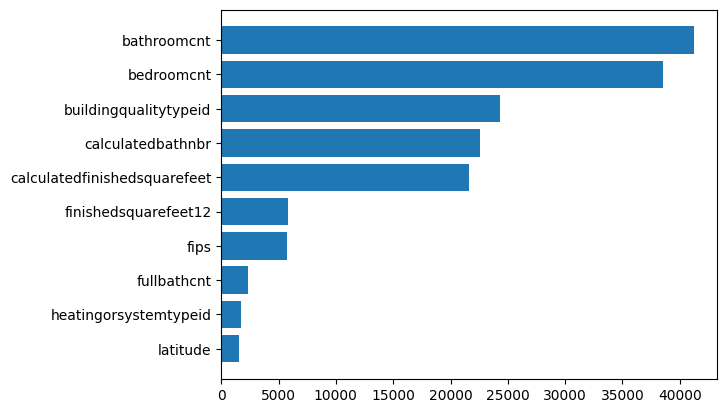

In [ ]:
# Plot for top scores

plt.barh(df_f_stats["Feature"][:10], df_f_stats["F_stat"][:10])
plt.gca().invert_yaxis()

In [ ]:
# Forward Selections

model = RandomForestRegressor(random_state = 42)

for_selection = SequentialFeatureSelector(model, n_features_to_select = 5, direction = "forward", cv = 3)

for_selection.fit(X, y)

features_selected = X.columns[for_selection.get_support()]

print("Forward Selections: ", features_selected)

Forward Selections:  Index(['calculatedbathnbr', 'fullbathcnt', 'propertylandusetypeid',
       'regionidcity', 'regionidzip'],
      dtype='object')


In [ ]:
# Backward Selections

model = RandomForestRegressor(random_state = 42)

ba_selection = SequentialFeatureSelector(model, n_features_to_select = 1, direction = "backward", cv = 3)

ba_selection.fit(X, y)

ba_selected = X.columns[ba_selection.get_support()]

print("Backward Selections: ", ba_selected)

#### **4.A Discussion:**  Describe in a paragraph what you see in the feature relationships and correlations.

Pay particular attention to especially interesting and/or strongly correlated feature relationships.
 How do the different methods for seeing relationships compare? Do they agree or disagree?



The correlation analysis showed that size-related features such as finishedsquarefeet12 and calculatedfinishedsquarefeet have the strongest positive relationship with taxvaluedollarcnt. Features like bathroomcnt and bedroomcnt also showed moderate correlations, indicating that larger homes tend to have higher values. The F-statistic results supported these findings, identifying the same features as the most important predictors. Forward feature selection further suggested that a small number of features can explain much of the variation, indicating some redundancy among highly correlated variables.

### Part 4.B:  2-Dimensional Visualizations for Interesting Patterns  
   - Select three (3) pairs of features that exhibit meaningful relationships based on your previous analysis.
   - Create 2D scatter plots or density plots to explore interactions between these features.  
   - Provide brief interpretations of any observed patterns or trends.

Text(0.5, 1.0, 'Finished Square Feet vs Tax Value')

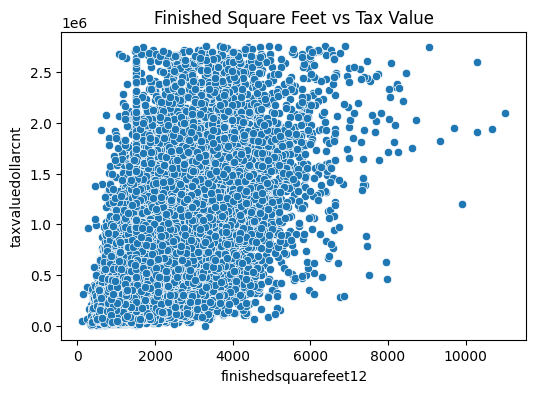

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df_impute, x='finishedsquarefeet12', y='taxvaluedollarcnt')
plt.title("Finished Square Feet vs Tax Value")

Text(0.5, 1.0, 'Bathrooms vs Tax Value')

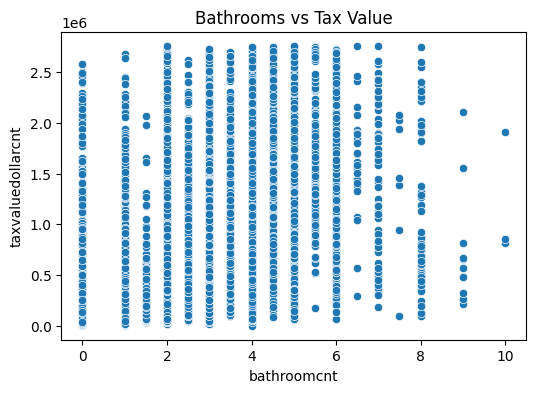

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df_impute, x='bathroomcnt', y='taxvaluedollarcnt')
plt.title("Bathrooms vs Tax Value")

Text(0.5, 1.0, 'Latitude vs Tax Value')

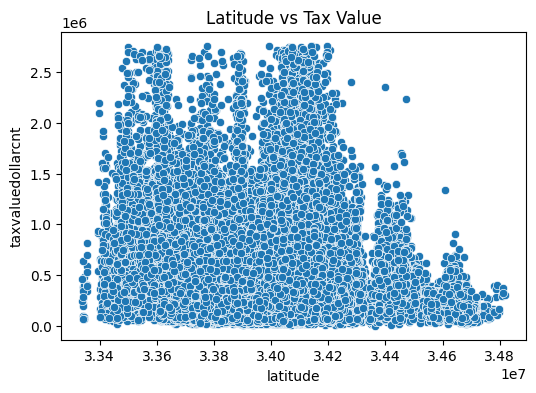

In [ ]:
plt.figure(figsize=(6,4))
sns.scatterplot(data=df_impute, x='latitude', y='taxvaluedollarcnt')
plt.title("Latitude vs Tax Value")

#### **4.B Discussion:** Provide brief interpretations of any observed patterns or trends.


The scatter plot of finishedsquarefeet12 versus taxvaluedollarcnt shows a clear positive relationship, where larger homes generally have higher property values, although there is noticeable spread indicating other factors also influence price. The relationship between bathroomcnt and taxvaluedollarcnt appears positive but less linear, with vertical clustering due to the discrete nature of bathroom counts and diminishing impact at higher values. The latitude plot shows distinct clusters rather than a linear trend, suggesting that geographic location plays a significant role in property values, with certain regions corresponding to higher-priced homes.

## Part 5:  Feature Engineering: Investigate various transformations to better expose the underlying data patterns to machine learning algorithms. [6 pts]

**Important Notes:**  
- This last part is a bit open ended, since there is a huge variety of feature engineering techniques, most of which won't be useful for your particular dataset.
- Understand that you can't evaluate the final usefulness of these transformations
until you choose a model, and  models may respond differently to various transformations or obviate some transformations (e.g., ensemble methods already do feature selection).
- Therefore, write your transformations as functions or otherwise be prepared
to choose later on which transformations may be necessary.

**Investigate feature engineering, where appropriate:**

- Feature scaling: standardize or normalize features as necessary
- Decompose features (e.g., categorical into One-Hot feature sequence, date/time into two features data and time, etc.).
- Add promising transformations of features
    - Exponential $\exp(x_i)$ or logarithmic $\log(x_j)$
    - Polynomial features  ( $x_i^2$, $x_i - x_j$), products ($x_i*x_j$), or ratios ($x_i/x_j$)

**ToDo:**
- Pick at least three transformations to try.
- Try each one and evaluate its effect using correlations or F-scores or a feature selection algorithm.
- Answer the discussion question.

In [ ]:
def get_feature_ratio(df, feature1, feature2):
  return df[feature1] / df[feature2]

def get_feature_diff(df, feature1, feature2):
  return df[feature1] - df[feature2]

def add_density_feature_columns_to_dataframe(df) -> pl.DataFrame:
    tree = cKDTree(df[["latitude", "longitude"]])
    result = pl.Series(
            "spatial_density",
            tree.query_ball_point(df[["latitude", "longitude"]], .5, return_length=True)
        )
    return result
df_fe = df_relations.copy()
df_fe['finishedsquarefeetratio'] = get_feature_ratio(df_relations, 'finishedsquarefeet12', 'calculatedfinishedsquarefeet')
df_fe['yeardiff'] = get_feature_diff(df_relations, 'assessmentyear', 'yearbuilt')
df_fe['spatial_density'] = add_density_feature_columns_to_dataframe(df_relations)
df_fe['logtaxvaluedollarcnt'] = np.log10(df_relations['taxvaluedollarcnt'])

# Splitting X and y into values
X_fe = df_fe.drop(columns = ['logtaxvaluedollarcnt', 'taxvaluedollarcnt'])
y_fe = df_fe['logtaxvaluedollarcnt']

In [ ]:
kbest = SelectKBest()
kbest.fit(X_fe, y_fe)
pd.DataFrame({"Features": X_fe.columns, "Scores": kbest.scores_}).sort_values(by="Scores", ascending=False).reset_index(drop=True)

/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [20] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.12/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


,Features,Scores
0,finishedsquarefeet12,3.604762
1,calculatedfinishedsquarefeet,3.310020
2,regionidcounty,2.061559
3,calculatedbathnbr,1.902229
4,bathroomcnt,1.870283
5,fullbathcnt,1.819026
6,roomcnt,1.714578
7,fips,1.513477
8,rawcensustractandblock,1.511228
9,regionidzip,1.506329


#### **5 Discussion:** Describe in a paragraph why you chose these transformations and what you observed.


I chose the finished square feet ratio transformation because I wanted to see how impactful the ratio between finished living room space and the total finished living room space was, since they had very high F-scores. I chose the year difference feature because I supposed that the time between when a year was built and when it was assessed would make more of a difference than each feature independently, as I thought the relevance of either would be relative to the other one. I chose the spatial density feature after seeing it used effectively for latitude and longitude in an article on a Miami housing dataset. I chose to apply the logarithm to the target column because of how high the dollar numbers are and their variance. I observed that the three features I adjusted had very low scores using the K-Best algorithm, but there were some differences with KBest and the log transformation on the other features. regionidcounty was one of the most important features according to the algorithm, and the square feet and bathroom count features were shuffled around.

## **Appendix 1: Features of the Zillow Dataset**  

0. **parcelid**: Unique identifier for the property parcel.  
1. **airconditioningtypeid**: Identifier for the type of air conditioning installed.  
2. **architecturalstyletypeid**: Identifier for the architectural style of the property.  
3. **basementsqft**: Square footage of the basement.  
4. **bathroomcnt**: Number of bathrooms.  
5. **bedroomcnt**: Number of bedrooms.  
6. **buildingclasstypeid**: Identifier for the building framing type (e.g., wood frame, steel frame).  
7. **buildingqualitytypeid**: Numeric value indicating the quality of the building (higher values often indicate better quality).  
8. **calculatedbathnbr**: Calculated number of bathrooms, including fractional bathrooms.  
9. **decktypeid**: Identifier for the type of deck.  
10. **finishedfloor1squarefeet**: Square footage of the finished area on the first floor.  
11. **calculatedfinishedsquarefeet**: Total finished living area square footage.  
12. **finishedsquarefeet12**: Finished living area square footage.  
13. **finishedsquarefeet13**: Perimeter living area square footage.  
14. **finishedsquarefeet15**: Total area.  
15. **finishedsquarefeet50**: Square footage of the finished area on the upper floors.  
16. **finishedsquarefeet6**: Base unfinished and finished area square footage.  
17. **fips**: Federal Information Processing Standards code, uniquely identifying counties and county equivalents.  
18. **fireplacecnt**: Number of fireplaces.  
19. **fullbathcnt**: Number of full bathrooms.  
20. **garagecarcnt**: Number of cars that can fit in the garage.  
21. **garagetotalsqft**: Total square footage of the garage.  
22. **hashottuborspa**: Indicates if the property has a hot tub or spa.  
23. **heatingorsystemtypeid**: Identifier for the type of heating system.  
24. **latitude**: Latitude coordinate of the property.  
25. **longitude**: Longitude coordinate of the property.  
26. **lotsizesquarefeet**: Lot size in square feet.  
27. **poolcnt**: Number of pools on the property.  
28. **poolsizesum**: Total square footage of all pools.  
29. **pooltypeid10**: Identifier for spa or hot tub.  
30. **pooltypeid2**: Identifier for pool with spa or hot tub.  
31. **pooltypeid7**: Identifier for pool without hot tub or spa.  
32. **propertycountylandusecode**: County land use code for the property.  
33. **propertylandusetypeid**: Identifier for the property land use type.  
34. **propertyzoningdesc**: Description of the property's zoning.  
35. **rawcensustractandblock**: Unprocessed census tract and block identifier.  
36. **regionidcity**: Identifier for the city.  
37. **regionidcounty**: Identifier for the county.  
38. **regionidneighborhood**: Identifier for the neighborhood.  
39. **regionidzip**: Identifier for the ZIP code.  
40. **roomcnt**: Total number of rooms.  
41. **storytypeid**: Identifier for the type of stories in the building (e.g., basement, attic).  
42. **threequarterbathnbr**: Number of 3/4 bathrooms (typically includes a shower but no tub).  
43. **typeconstructiontypeid**: Identifier for the type of construction (e.g., frame, masonry).  
44. **unitcnt**: Number of units in the building (e.g., for multi-family properties).  
45. **yardbuildingsqft17**: Square footage of the 17th yard building (e.g., shed).  
46. **yardbuildingsqft26**: Square footage of the 26th yard building.  
47. **yearbuilt**: Year the property was built.  
48. **numberofstories**: Number of stories in the building.  
49. **fireplaceflag**: Indicates if the property has a fireplace.  
50. **assessmentyear**: Year the property was assessed.  
51. **taxdelinquencyflag**: Indicates whether the property’s taxes are delinquent. Often “Y” if taxes are past due; otherwise null/empty.  
52. **taxdelinquencyyear**: The year in which the property’s taxes became delinquent.  
53. **censustractandblock**: A combined identifier for the property’s census tract and block group (part of the U.S. Census geographic hierarchy).  
54. **taxvaluedollarcnt**: Total assessed value of the property (land plus structure) in dollars.  


## Appendix 2: Summary of Basic Imputation Methods
Imputation depends on the data type and context. Below are common techniques for handling missing values.

---

### **1. Simple Imputation (Basic Methods)**
| Method | Best For | Code Example | Pros | Cons |
|--------|---------|--------------|------|------|
| **Drop Missing Values** | Few missing values (<5% of data) | `df.dropna()` | Quick and easy | Can remove valuable data |
| **Mean Imputation** | Normally distributed numerical data | `df.fillna(df.mean())` | Preserves mean; simple | Distorts variance, weak for skewed data |
| **Median Imputation** | Skewed numerical data | `df.fillna(df.median())` | Robust to outliers | May not capture patterns |
| **Mode Imputation** | Categorical features | `df.fillna(df.mode().iloc[0])` | Keeps most common category | Can introduce bias |
| **Constant Value (e.g., 0)** | Special cases (e.g., unknown numerical data) | `df.fillna(0)` | Simple and interpretable | Can mislead model |
| **"Unknown" Category Imputation** (**New Addition**) | Categorical features with missing values | `df.fillna('Unknown')` | Keeps all rows, prevents data loss | May introduce artificial category |

---

### **2. Statistical & Advanced Imputation**
| Method | Best For | Code Example | Pros | Cons |
|--------|---------|--------------|------|------|
| **Interpolation** | Time series, ordered data | `df.interpolate(method='linear')` | Preserves trends | May not work for non-continuous data |
| **K-Nearest Neighbors (KNN)** | Small datasets, patterns in features | `KNNImputer(n_neighbors=5).fit_transform(df)` | Uses similar observations | Computationally expensive |
| **Multivariate Imputation (MICE)** | Complex relationships between variables | `IterativeImputer().fit_transform(df)` | Captures relationships | Slower than mean/median |
| **Regression Imputation** | When missing values depend on other variables | Train regression model to predict missing values | More accurate than mean/median | Risk of overfitting |

---

### **When to Use "Unknown" Category for Categorical Imputation**
✅ **Good for:**
- Categorical features where missing values may indicate meaningful differences.  
- Customer data (e.g., missing survey responses → "No Response").  
- Product categories where missing could be a separate group.  

❌ **Avoid if:**
- The missing category does **not** have a meaningful interpretation.
- The model might learn spurious patterns from an artificial category.

---

### **Which Method to Choose?**
| Scenario | Best Method |
|----------|------------|
| **Few missing values (<5%)** | Drop NaNs (`df.dropna()`) |
| **Numerical & normal distribution** | Mean (`df.fillna(df.mean())`) |
| **Numerical & skewed distribution** | Median (`df.fillna(df.median())`) |
| **Categorical features** | Mode (`df.fillna(df.mode().iloc[0])`) |
| **Categorical with possible meaning in missingness** | "Unknown" Category (`df.fillna('Unknown')`) |
| **Small dataset with patterns** | KNN Imputer (`KNNImputer()`) |
| **Complex relationships between features** | MICE / Iterative Imputer |

